# STAT3612 Tutorial 09 — Unsupervised Learning: Dimensionality Reduction & Clustering

**STAT3612: Statistical Machine Learning (Fall 2026, HKU)**  
**Instructor / TA:** Yinghao Zhu

---

## Big-Picture Overview: Why Unsupervised Learning?
In Weeks 1–10, we studied **Supervised Learning**: given labeled pairs $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$, we fit a model $f(\mathbf{x})$ to predict target $\hat{y}_i$. In real-world data science, however, **ground-truth labels $y_i$ are often scarce or expensive**, while raw feature vectors $\{\mathbf{x}_i\}_{i=1}^n \in \mathbb{R}^d$ are abundant. Moreover, when $d$ is large, the **curse of dimensionality** causes Euclidean distances to concentrate and collinear features to destabilize estimators.

**Unsupervised Learning** discovers intrinsic structure in $\mathbf{X}$ *without using any labels $y_i$ during fitting* across two core pillars:
1. **Dimensionality Reduction ($\mathbb{R}^d \to \mathbb{R}^k, k \ll d$):** Compress redundant features into orthogonal axes (`PCA`), non-linear kernel manifolds (`KernelPCA`), or 2D neighborhood visualizations (`TSNE`).
2. **Clustering ($\mathbf{x}_i \mapsto \hat{c}_i \in \{1,\dots,K\}$):** Partition unlabeled points into homogeneous groups via Voronoi centroids (`KMeans`), hierarchical merge trees (`AgglomerativeClustering`), dense neighborhoods (`DBSCAN`), or soft elliptical probabilities (`GaussianMixture`).

---

### Notebook Outline
1. **Part 1 — Dimensionality Reduction:**
   - Exploring the 4D `Iris` feature space & collinearity structure
   - Why `StandardScaler` before `PCA` is mandatory (`Wine` 13D benchmark)
   - Scree plots (`explained_variance_ratio_`) and choosing the number of principal components $k$
   - 2D and 3D `PCA` projections of `Iris`
   - `PCA` (Unsupervised) vs. `LinearDiscriminantAnalysis` (`LDA`, Supervised)
   - Non-linear dimensionality reduction with `KernelPCA(kernel="rbf")` on concentric circles
   - Manifold learning for visualization: `PCA` vs. `TSNE` on 64D handwritten digits
2. **Part 2 — Clustering:**
   - `KMeans` alternating optimization and choosing $K$ via the **Inertia Elbow** and **Silhouette Score**
   - Failure mode of `KMeans` on non-convex shapes (`make_moons`) vs. `AgglomerativeClustering(linkage="single")` and `DBSCAN`
   - Hierarchical clustering & visualizing the merge tree with a `scipy` **Ward Dendrogram**
   - Probabilistic soft clustering with `GaussianMixture` (`GMM`) on elongated anisotropic clusters
   - Evaluating clustering quality: Internal (`silhouette_score`, `davies_bouldin_score`) vs. External (`adjusted_rand_score`, `normalized_mutual_info_score`) metrics
3. **Part 3 — Unsupervised Pipelines in Practice:**
   - **Pipeline I (PCA Denoising Before KNN):** `StandardScaler` $\to$ `PCA` scree plot $\to$ `KNeighborsClassifier` accuracy across $k$ retained components
   - **Pipeline II (Combining PCA & Clustering on High-D Data):** `StandardScaler` $\to$ `PCA` $\to$ `KMeans` / `GMM` on high-dimensional tabular data (`Breast Cancer` $d=30$)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.datasets import load_breast_cancer, load_digits, load_iris, load_wine, make_blobs, make_circles, make_moons
from sklearn.decomposition import KernelPCA, PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    davies_bouldin_score,
    log_loss,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

plt.rcParams["figure.dpi"] = 110
COLORS = ["#1f4e79", "#c0392b", "#1e8449", "#b9770e", "#7d3c98"]
print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## Part 1: Dimensionality Reduction (`PCA`, `KernelPCA`, `LDA`, `TSNE`)

### 1.1 Exploring the 4D Iris Dataset

In [2]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
names_iris = iris.target_names
df_iris = pd.DataFrame(X_iris, columns=iris.feature_names)
df_iris["species"] = [names_iris[i] for i in y_iris]
print("Iris shape:", X_iris.shape)
print("Pairwise correlation matrix:")
print(df_iris.iloc[:, :4].corr().round(3))

Iris shape: (150, 4)
Pairwise correlation matrix:
                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)              1.000            -0.118              0.872   
sepal width (cm)              -0.118             1.000             -0.428   
petal length (cm)              0.872            -0.428              1.000   
petal width (cm)               0.818            -0.366              0.963   

                   petal width (cm)  
sepal length (cm)             0.818  
sepal width (cm)             -0.366  
petal length (cm)             0.963  
petal width (cm)              1.000  


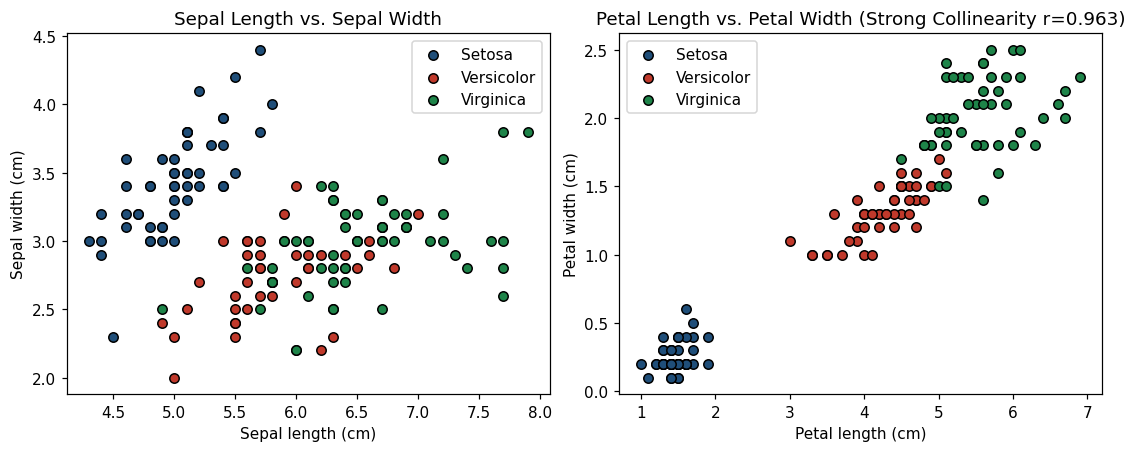

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
for idx, (c, name) in enumerate(zip(COLORS[:3], names_iris)):
    mask = y_iris == idx
    axs[0].scatter(X_iris[mask, 0], X_iris[mask, 1], c=c, label=name.capitalize(), edgecolors="k", s=38)
    axs[1].scatter(X_iris[mask, 2], X_iris[mask, 3], c=c, label=name.capitalize(), edgecolors="k", s=38)
axs[0].set_title("Sepal Length vs. Sepal Width")
axs[0].set_xlabel("Sepal length (cm)")
axs[0].set_ylabel("Sepal width (cm)")
axs[0].legend()
axs[1].set_title("Petal Length vs. Petal Width (Strong Collinearity r=0.963)")
axs[1].set_xlabel("Petal length (cm)")
axs[1].set_ylabel("Petal width (cm)")
axs[1].legend()
plt.show()

### 1.2 Step 1: Why `StandardScaler` Before `PCA` Is Mandatory
Because PCA maximizes projected variance $\mathbf{w}^\top \mathbf{S} \mathbf{w}$, any feature measured in large numerical units will dominate the first principal component unless all features are standardized to zero mean and unit variance first.

Unscaled EVR (first 2 PCs): [0.9981 0.0017]
Standardized EVR (first 2 PCs): [0.362  0.1921]


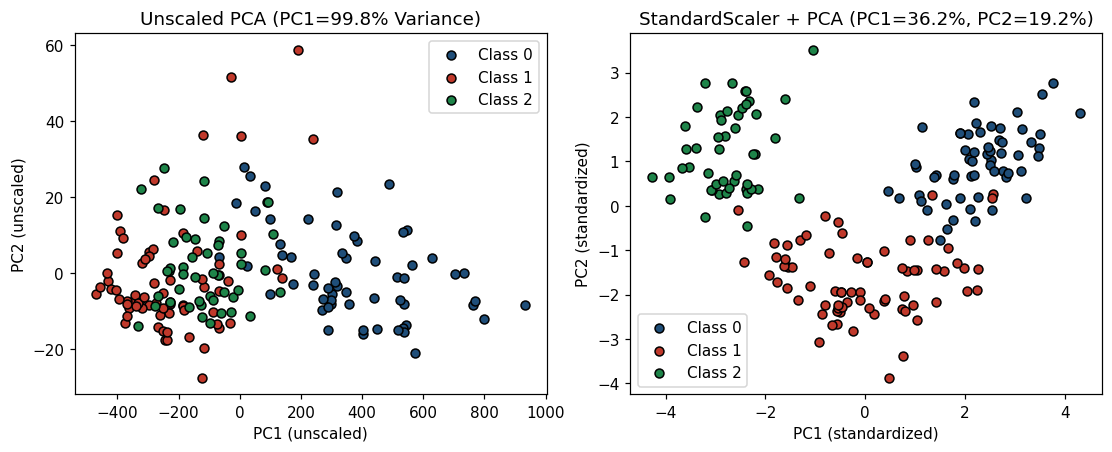

In [4]:
wine = load_wine()
X_wine, y_wine = wine.data, wine.target

pca_raw = PCA(n_components=2).fit(X_wine)
Z_raw = pca_raw.transform(X_wine)

X_wine_std = StandardScaler().fit_transform(X_wine)
pca_std = PCA(n_components=2).fit(X_wine_std)
Z_std = pca_std.transform(X_wine_std)

print("Unscaled EVR (first 2 PCs):", np.round(pca_raw.explained_variance_ratio_, 4))
print("Standardized EVR (first 2 PCs):", np.round(pca_std.explained_variance_ratio_, 4))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
for idx, c in enumerate(COLORS[:3]):
    mask = y_wine == idx
    axs[0].scatter(Z_raw[mask, 0], Z_raw[mask, 1], c=c, label=f"Class {idx}", edgecolors="k", s=34)
    axs[1].scatter(Z_std[mask, 0], Z_std[mask, 1], c=c, label=f"Class {idx}", edgecolors="k", s=34)
axs[0].set_title(f"Unscaled PCA (PC1={pca_raw.explained_variance_ratio_[0]*100:.1f}% Variance)")
axs[0].set_xlabel("PC1 (unscaled)")
axs[0].set_ylabel("PC2 (unscaled)")
axs[0].legend()
axs[1].set_title(f"StandardScaler + PCA (PC1={pca_std.explained_variance_ratio_[0]*100:.1f}%, PC2={pca_std.explained_variance_ratio_[1]*100:.1f}%)")
axs[1].set_xlabel("PC1 (standardized)")
axs[1].set_ylabel("PC2 (standardized)")
axs[1].legend()
plt.show()

### 1.3 Step 2: Scree Plot & Cumulative Explained Variance Ratio

Iris smallest k retaining >=95% variance: k=2 (95.81%)


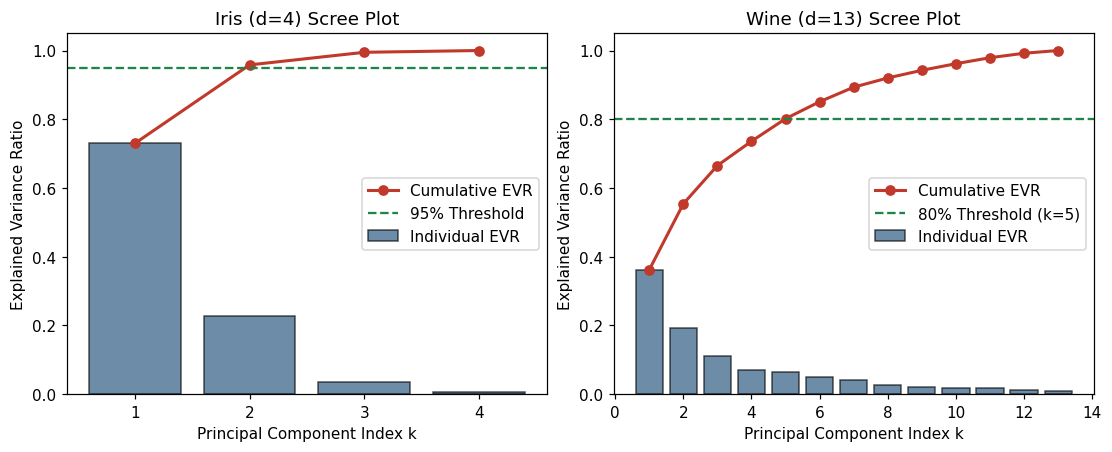

In [5]:
X_iris_std = StandardScaler().fit_transform(X_iris)
pca_iris_full = PCA().fit(X_iris_std)
pca_wine_full = PCA().fit(X_wine_std)

pca_95 = PCA(n_components=0.95).fit(X_iris_std)
print(f"Iris smallest k retaining >=95% variance: k={pca_95.n_components_} ({pca_95.explained_variance_ratio_.sum()*100:.2f}%)")

fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
ev_i = pca_iris_full.explained_variance_ratio_
ks_i = np.arange(1, len(ev_i) + 1)
axs[0].bar(ks_i, ev_i, alpha=0.65, color="#1f4e79", edgecolor="k", label="Individual EVR")
axs[0].plot(ks_i, np.cumsum(ev_i), "o-", color="#c0392b", lw=2.0, label="Cumulative EVR")
axs[0].axhline(0.95, color="#1e8449", ls="--", label="95% Threshold")
axs[0].set_xticks(ks_i)
axs[0].set_title("Iris (d=4) Scree Plot")
axs[0].set_xlabel("Principal Component Index k")
axs[0].set_ylabel("Explained Variance Ratio")
axs[0].legend()

ev_w = pca_wine_full.explained_variance_ratio_
ks_w = np.arange(1, len(ev_w) + 1)
axs[1].bar(ks_w, ev_w, alpha=0.65, color="#1f4e79", edgecolor="k", label="Individual EVR")
axs[1].plot(ks_w, np.cumsum(ev_w), "o-", color="#c0392b", lw=2.0, label="Cumulative EVR")
axs[1].axhline(0.80, color="#1e8449", ls="--", label="80% Threshold (k=5)")
axs[1].set_title("Wine (d=13) Scree Plot")
axs[1].set_xlabel("Principal Component Index k")
axs[1].set_ylabel("Explained Variance Ratio")
axs[1].legend()
plt.show()

### 1.4 Step 3: 2D & 3D PCA Projections of the Iris Dataset

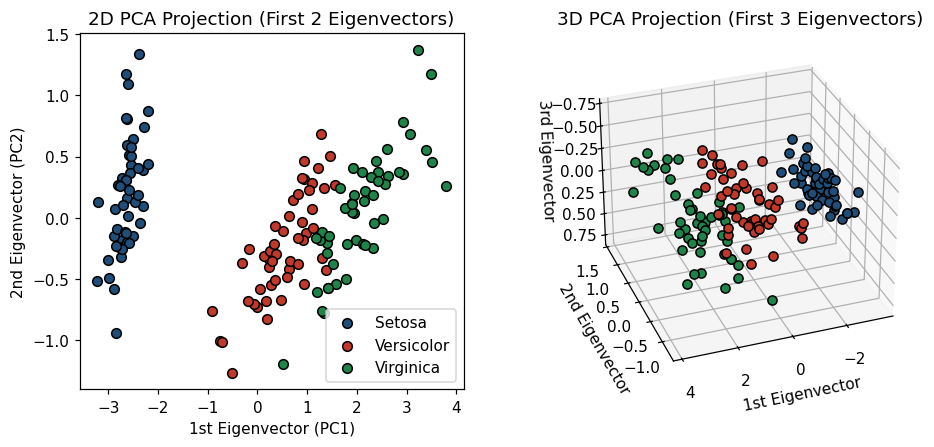

In [6]:
X_reduced = PCA(n_components=3).fit_transform(X_iris)

fig = plt.figure(figsize=(10, 4.2))
fig.subplots_adjust(wspace=0.22)
ax2d = fig.add_subplot(1, 2, 1)
for idx, (c, name) in enumerate(zip(COLORS[:3], names_iris)):
    mask = y_iris == idx
    ax2d.scatter(X_reduced[mask, 0], X_reduced[mask, 1], c=c, label=name.capitalize(), edgecolors="k", s=40)
ax2d.set_title("2D PCA Projection (First 2 Eigenvectors)")
ax2d.set_xlabel("1st Eigenvector (PC1)")
ax2d.set_ylabel("2nd Eigenvector (PC2)")
ax2d.legend()

ax3d = fig.add_subplot(1, 2, 2, projection="3d", elev=-150, azim=110)
for idx, (c, name) in enumerate(zip(COLORS[:3], names_iris)):
    mask = y_iris == idx
    ax3d.scatter(
        X_reduced[mask, 0], X_reduced[mask, 1], X_reduced[mask, 2],
        c=c, label=name.capitalize(), edgecolors="k", s=36, depthshade=False
    )
ax3d.set_title("3D PCA Projection (First 3 Eigenvectors)")
ax3d.set_xlabel("1st Eigenvector")
ax3d.set_ylabel("2nd Eigenvector")
ax3d.set_zlabel("3rd Eigenvector")
plt.show()

### 1.5 `PCA` (Unsupervised) vs. `LDA` (Supervised) on Iris
- **PCA** ignores labels $y$ and identifies directions of maximum total variance.
- **LDA** uses labels $y$ to maximize the ratio of between-class scatter to within-class scatter.

PCA explained variance ratio (first two components): [0.9246 0.0531]


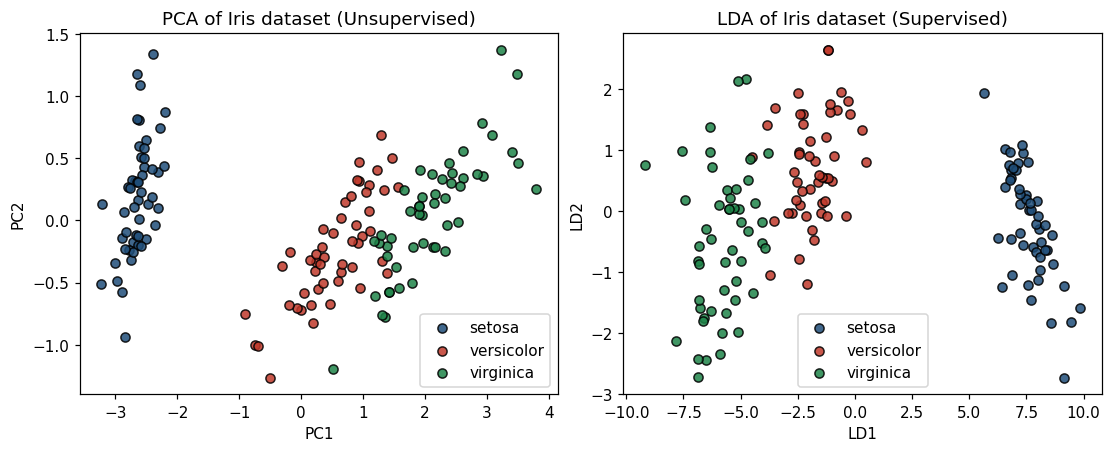

In [7]:
pca_2 = PCA(n_components=2)
X_r_pca = pca_2.fit(X_iris).transform(X_iris)

lda_2 = LinearDiscriminantAnalysis(n_components=2)
X_r_lda = lda_2.fit(X_iris, y_iris).transform(X_iris)

print("PCA explained variance ratio (first two components):", np.round(pca_2.explained_variance_ratio_, 4))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
for idx, (c, name) in enumerate(zip(COLORS[:3], names_iris)):
    mask = y_iris == idx
    axs[0].scatter(X_r_pca[mask, 0], X_r_pca[mask, 1], color=c, alpha=0.85, lw=1, edgecolors="k", label=name)
    axs[1].scatter(X_r_lda[mask, 0], X_r_lda[mask, 1], color=c, alpha=0.85, lw=1, edgecolors="k", label=name)
axs[0].set_title("PCA of Iris dataset (Unsupervised)")
axs[0].set_xlabel("PC1")
axs[0].set_ylabel("PC2")
axs[0].legend()
axs[1].set_title("LDA of Iris dataset (Supervised)")
axs[1].set_xlabel("LD1")
axs[1].set_ylabel("LD2")
axs[1].legend()
plt.show()

### 1.6 Non-Linear Dimensionality Reduction: `KernelPCA` on Concentric Circles
When classes lie on concentric non-linear rings, standard linear `PCA` only rotates the coordinate axes. `KernelPCA(kernel="rbf", gamma=10)` maps the data implicitly into a high-dimensional RKHS where the rings become linearly separable along the first Kernel PC.

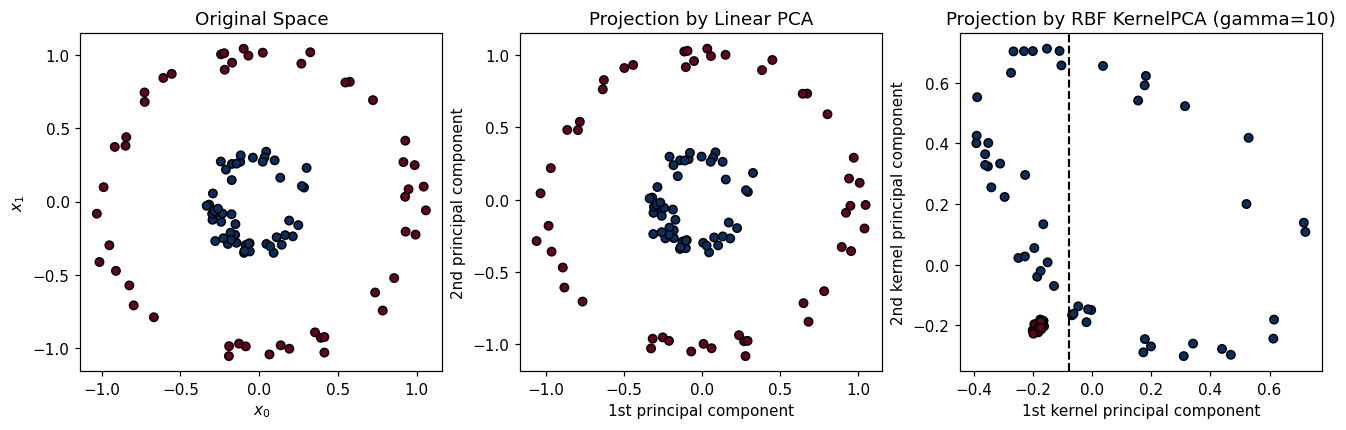

In [8]:
X_circ, y_circ = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=0)
X_ctr, X_cte, y_ctr, y_cte = train_test_split(X_circ, y_circ, stratify=y_circ, random_state=0)

pca_c = PCA(n_components=2).fit(X_ctr)
kpca_c = KernelPCA(n_components=None, kernel="rbf", gamma=10, fit_inverse_transform=True, alpha=0.1).fit(X_ctr)

X_test_pca = pca_c.transform(X_cte)
X_test_kpca = kpca_c.transform(X_cte)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
axs[0].scatter(X_cte[:, 0], X_cte[:, 1], c=y_cte, cmap=plt.cm.RdBu, edgecolors="k", s=30)
axs[0].set_title("Original Space")
axs[0].set_xlabel("$x_0$")
axs[0].set_ylabel("$x_1$")

axs[1].scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_cte, cmap=plt.cm.RdBu, edgecolors="k", s=30)
axs[1].set_title("Projection by Linear PCA")
axs[1].set_xlabel("1st principal component")
axs[1].set_ylabel("2nd principal component")

axs[2].scatter(X_test_kpca[:, 0], X_test_kpca[:, 1], c=y_cte, cmap=plt.cm.RdBu, edgecolors="k", s=30)
axs[2].axvline(-0.08, color="k", ls="--", lw=1.4)
axs[2].set_title("Projection by RBF KernelPCA (gamma=10)")
axs[2].set_xlabel("1st kernel principal component")
axs[2].set_ylabel("2nd kernel principal component")
plt.show()

### 1.7 Manifold Learning for Visualization: `PCA` vs. `TSNE` on 64D Digits

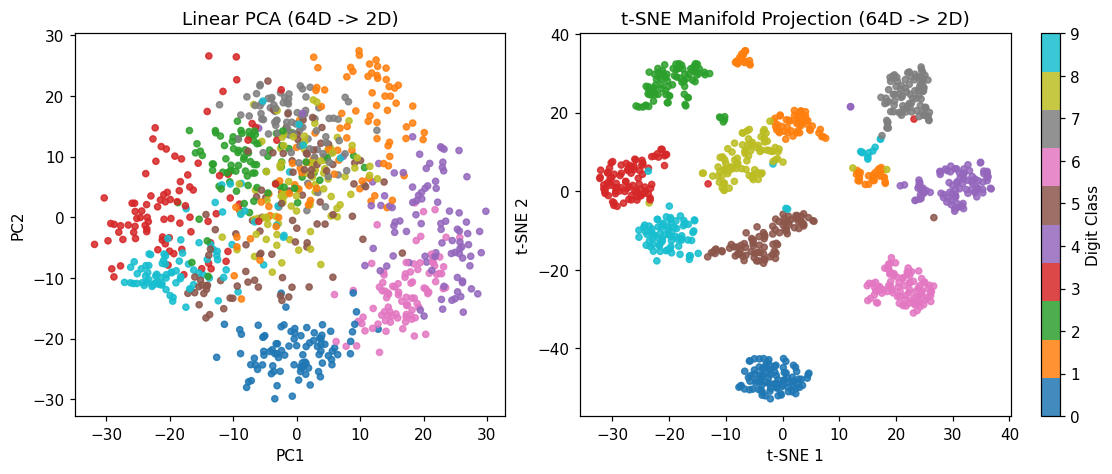

In [9]:
digits = load_digits()
X_dig, y_dig = digits.data[::2], digits.target[::2]

Z_dig_pca = PCA(n_components=2, random_state=42).fit_transform(X_dig)
Z_dig_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(X_dig)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
axs[0].scatter(Z_dig_pca[:, 0], Z_dig_pca[:, 1], c=y_dig, cmap="tab10", s=16, alpha=0.85)
axs[0].set_title("Linear PCA (64D -> 2D)")
axs[0].set_xlabel("PC1")
axs[0].set_ylabel("PC2")

sc = axs[1].scatter(Z_dig_tsne[:, 0], Z_dig_tsne[:, 1], c=y_dig, cmap="tab10", s=16, alpha=0.85)
axs[1].set_title("t-SNE Manifold Projection (64D -> 2D)")
axs[1].set_xlabel("t-SNE 1")
axs[1].set_ylabel("t-SNE 2")
fig.colorbar(sc, ax=axs[1], ticks=range(10), label="Digit Class")
plt.show()

---
## Part 2: Clustering (`KMeans`, `AgglomerativeClustering`, `DBSCAN`, `GaussianMixture`)

### 2.1 `KMeans` & Choosing $K$: Inertia Elbow vs. Silhouette Score

Optimal K by Silhouette Score: K=3 (score=0.6617)


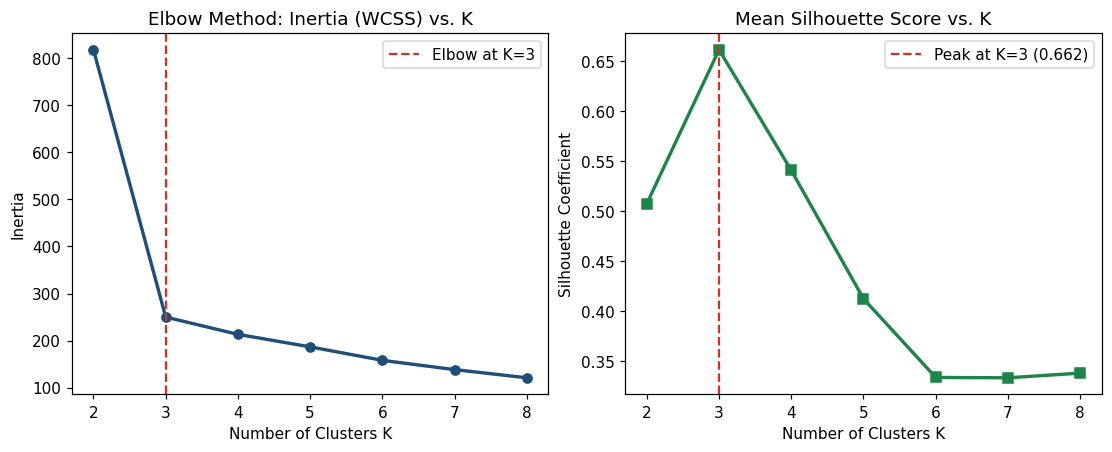

In [10]:
X_blobs, y_blobs = make_blobs(
    n_samples=240, centers=[[-2.2, -1.2], [2.0, -1.0], [0.2, 2.3]],
    cluster_std=[0.75, 0.75, 0.75], random_state=42
)

ks = list(range(2, 9))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_blobs)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_blobs, km.labels_))

best_k = ks[int(np.argmax(silhouettes))]
print(f"Optimal K by Silhouette Score: K={best_k} (score={max(silhouettes):.4f})")

fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
axs[0].plot(ks, inertias, "o-", color="#1f4e79", lw=2.2)
axs[0].axvline(3, color="#c0392b", ls="--", label="Elbow at K=3")
axs[0].set_title("Elbow Method: Inertia (WCSS) vs. K")
axs[0].set_xlabel("Number of Clusters K")
axs[0].set_ylabel("Inertia")
axs[0].legend()

axs[1].plot(ks, silhouettes, "s-", color="#1e8449", lw=2.2)
axs[1].axvline(3, color="#c0392b", ls="--", label=f"Peak at K=3 ({max(silhouettes):.3f})")
axs[1].set_title("Mean Silhouette Score vs. K")
axs[1].set_xlabel("Number of Clusters K")
axs[1].set_ylabel("Silhouette Coefficient")
axs[1].legend()
plt.show()

### 2.2 Diagnostic: When `KMeans` Fails on Non-Convex Shapes (`make_moons`)

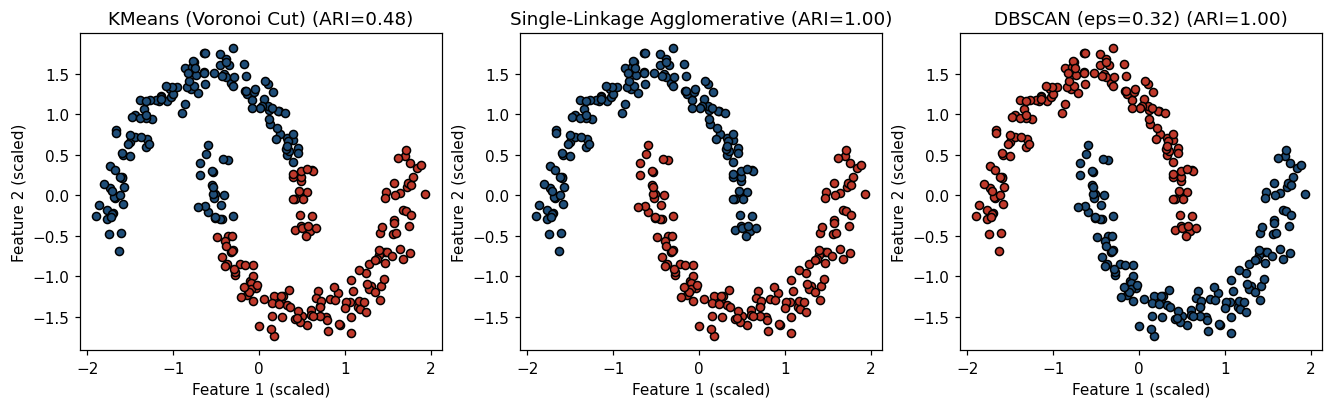

In [11]:
X_m, y_m = make_moons(n_samples=300, noise=0.07, random_state=42)
X_m_std = StandardScaler().fit_transform(X_m)

km_m = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_m_std)
agg_m = AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(X_m_std)
db_m = DBSCAN(eps=0.32, min_samples=5).fit_predict(X_m_std)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, preds, name in zip(
    axs,
    [km_m, agg_m, db_m],
    ["KMeans (Voronoi Cut)", "Single-Linkage Agglomerative", "DBSCAN (eps=0.32)"],
):
    ari = adjusted_rand_score(y_m, preds)
    for lbl in np.unique(preds):
        c = "#7f8c8d" if lbl == -1 else COLORS[lbl % len(COLORS)]
        ax.scatter(X_m_std[preds == lbl, 0], X_m_std[preds == lbl, 1], c=c, edgecolors="k", s=28)
    ax.set_title(f"{name} (ARI={ari:.2f})")
    ax.set_xlabel("Feature 1 (scaled)")
    ax.set_ylabel("Feature 2 (scaled)")
plt.show()

### 2.3 Hierarchical Clustering & Ward Dendrogram

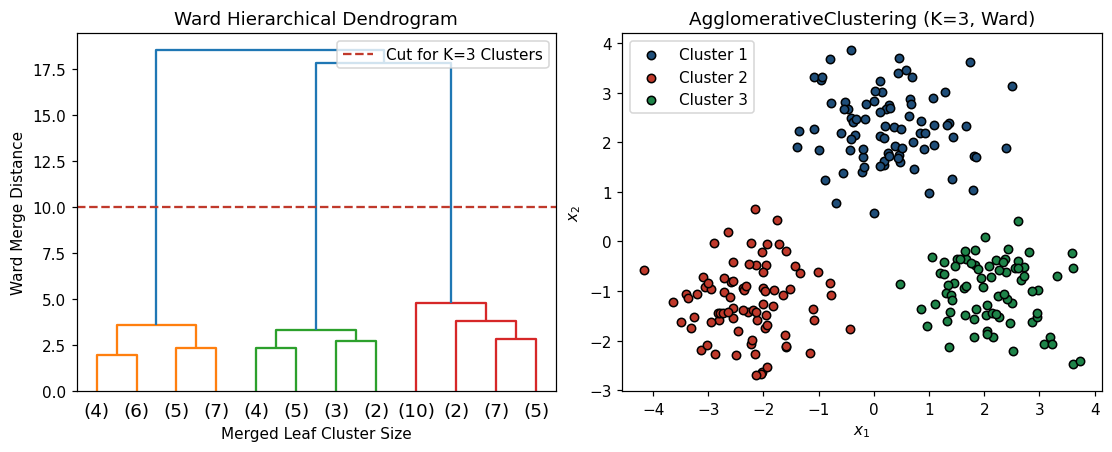

In [12]:
Z_link = linkage(X_blobs[::4], method="ward")
agg_blobs = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_blobs)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
dendrogram(Z_link, truncate_mode="lastp", p=12, color_threshold=10.0, ax=axs[0])
axs[0].axhline(10.0, color="#c0392b", ls="--", label="Cut for K=3 Clusters")
axs[0].set_title("Ward Hierarchical Dendrogram")
axs[0].set_xlabel("Merged Leaf Cluster Size")
axs[0].set_ylabel("Ward Merge Distance")
axs[0].legend()

for k in range(3):
    axs[1].scatter(X_blobs[agg_blobs == k, 0], X_blobs[agg_blobs == k, 1], c=COLORS[k], edgecolors="k", s=30, label=f"Cluster {k+1}")
axs[1].set_title("AgglomerativeClustering (K=3, Ward)")
axs[1].set_xlabel("$x_1$")
axs[1].set_ylabel("$x_2$")
axs[1].legend()
plt.show()

### 2.4 Probabilistic Soft Clustering: `GaussianMixture` (GMM) on Elongated Ellipses

Sample soft cluster responsibilities (first 3 points):
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]


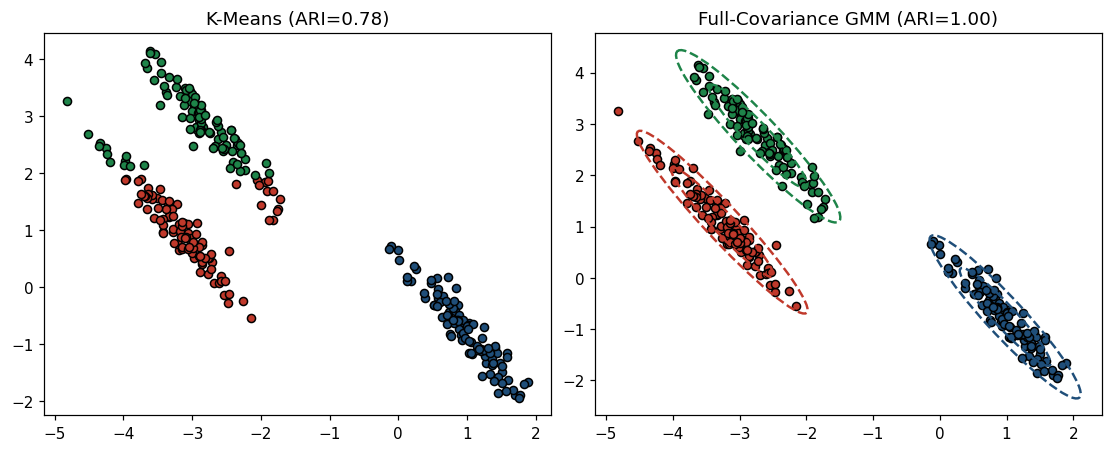

In [13]:
X_raw_b, y_raw_b = make_blobs(n_samples=300, centers=3, cluster_std=0.65, random_state=170)
X_aniso = X_raw_b @ np.array([[0.6, -0.6], [-0.4, 0.8]])

km_aniso = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_aniso)
gmm_aniso = GaussianMixture(n_components=3, covariance_type="full", random_state=42).fit(X_aniso)
gmm_labels = gmm_aniso.predict(X_aniso)
gmm_probs = gmm_aniso.predict_proba(X_aniso)
print("Sample soft cluster responsibilities (first 3 points):\n", np.round(gmm_probs[:3], 4))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
for k in range(3):
    axs[0].scatter(X_aniso[km_aniso.labels_ == k, 0], X_aniso[km_aniso.labels_ == k, 1], c=COLORS[k], edgecolors="k", s=28)
axs[0].set_title(f"K-Means (ARI={adjusted_rand_score(y_raw_b, km_aniso.labels_):.2f})")

for k in range(3):
    axs[1].scatter(X_aniso[gmm_labels == k, 0], X_aniso[gmm_labels == k, 1], c=COLORS[k], edgecolors="k", s=28)
    mean, cov = gmm_aniso.means_[k], gmm_aniso.covariances_[k]
    eigvals, eigvecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))
    for factor in [1.5, 2.5]:
        w, h = 2 * factor * np.sqrt(eigvals)
        axs[1].add_patch(Ellipse(xy=mean, width=w, height=h, angle=angle, edgecolor=COLORS[k], facecolor="none", lw=1.6, ls="--"))
axs[1].set_title(f"Full-Covariance GMM (ARI={adjusted_rand_score(y_raw_b, gmm_labels):.2f})")
plt.show()

### 2.5 Quantitative Comparison: Internal vs. External Clustering Metrics

In [14]:
rows = []
for name, labels in [("KMeans (Spherical)", km_aniso.labels_), ("GaussianMixture (Full Cov)", gmm_labels)]:
    rows.append({
        "Method": name,
        "Silhouette (Internal, higher=better)": round(silhouette_score(X_aniso, labels), 4),
        "Davies-Bouldin (Internal, lower=better)": round(davies_bouldin_score(X_aniso, labels), 4),
        "ARI (External, higher=better)": round(adjusted_rand_score(y_raw_b, labels), 4),
        "NMI (External, higher=better)": round(normalized_mutual_info_score(y_raw_b, labels), 4),
    })
print(pd.DataFrame(rows).to_string(index=False))

                    Method  Silhouette (Internal, higher=better)  Davies-Bouldin (Internal, lower=better)  ARI (External, higher=better)  NMI (External, higher=better)
        KMeans (Spherical)                                0.6051                                   0.5805                         0.7798                         0.7714
GaussianMixture (Full Cov)                                0.5999                                   0.6283                         1.0000                         1.0000


---
## Part 3: Unsupervised Pipelines in Practice

### 3.1 Pipeline I: Standardized `PCA` Denoising Before `KNeighborsClassifier`

In [15]:
X_wtr, X_wte, y_wtr, y_wte = train_test_split(
    X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=42
)
scaler_w = StandardScaler().fit(X_wtr)
X_wtr_s = scaler_w.transform(X_wtr)
X_wte_s = scaler_w.transform(X_wte)

pca_w = PCA().fit(X_wtr_s)
ks_all = list(range(1, X_wine.shape[1] + 1))
knn_accs = []
for k in ks_all:
    knn = KNeighborsClassifier(n_neighbors=5).fit(pca_w.transform(X_wtr_s)[:, :k], y_wtr)
    knn_accs.append(accuracy_score(y_wte, knn.predict(pca_w.transform(X_wte_s)[:, :k])))

best_k_knn = ks_all[int(np.argmax(knn_accs))]
print(f"Best KNN test accuracy: {max(knn_accs):.4f} using k={best_k_knn} principal components (vs. {knn_accs[-1]:.4f} with all 13 features).")

Best KNN test accuracy: 1.0000 using k=3 principal components (vs. 0.9444 with all 13 features).


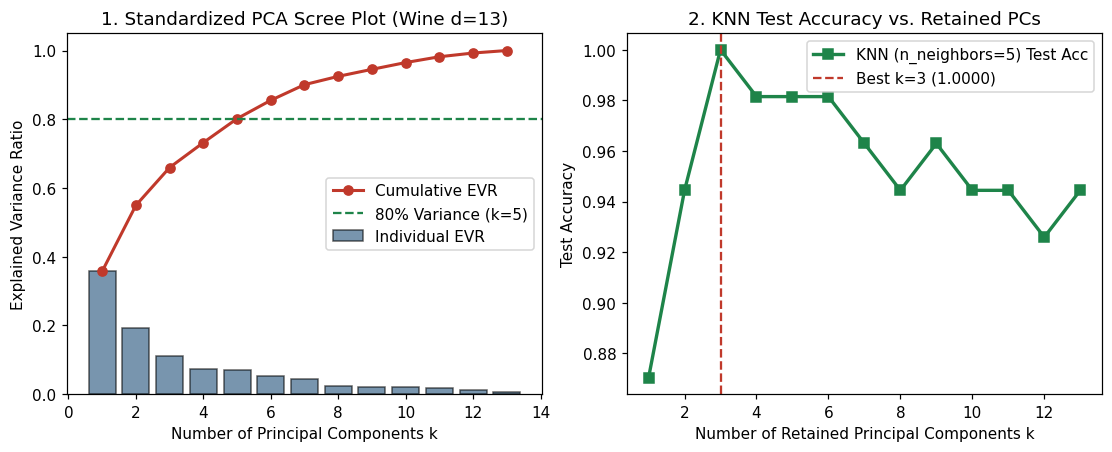

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.0), layout="constrained")
axs[0].bar(ks_all, pca_w.explained_variance_ratio_, alpha=0.6, color="#1f4e79", edgecolor="k", label="Individual EVR")
axs[0].plot(ks_all, np.cumsum(pca_w.explained_variance_ratio_), "o-", color="#c0392b", lw=2.0, label="Cumulative EVR")
axs[0].axhline(0.80, color="#1e8449", ls="--", label="80% Variance (k=5)")
axs[0].set_title("1. Standardized PCA Scree Plot (Wine d=13)")
axs[0].set_xlabel("Number of Principal Components k")
axs[0].set_ylabel("Explained Variance Ratio")
axs[0].legend()

axs[1].plot(ks_all, knn_accs, "s-", color="#1e8449", lw=2.2, label="KNN (n_neighbors=5) Test Acc")
axs[1].axvline(best_k_knn, color="#c0392b", ls="--", label=f"Best k={best_k_knn} ({max(knn_accs):.4f})")
axs[1].set_title("2. KNN Test Accuracy vs. Retained PCs")
axs[1].set_xlabel("Number of Retained Principal Components k")
axs[1].set_ylabel("Test Accuracy")
axs[1].legend()
plt.show()

### 3.2 Pipeline II: Combining `PCA` & Clustering on High-Dimensional Tabular Data
Below we load the 30-dimensional **Wisconsin Breast Cancer** dataset ($n=569, d=30$) and show how standardizing and projecting onto the top principal components before running `KMeans` or `GaussianMixture` improves both Silhouette Score and Adjusted Rand Index (ARI), and how unsupervised cluster-distance features can be computed leak-free inside cross-validation.

In [17]:
cancer = load_breast_cancer()
X_bc, y_bc = cancer.data, cancer.target
X_bc_s = StandardScaler().fit_transform(X_bc)
print("Breast Cancer feature matrix shape:", X_bc.shape, "| Class balance:", np.bincount(y_bc))

Breast Cancer feature matrix shape: (569, 30) | Class balance: [212 357]


In [18]:
pipeline_rows = []
for desc, Z_mat in [
    ("1. Raw Standardized (d=30) + KMeans(K=2)", X_bc_s),
    ("2. PCA (k=5, 84% var) + KMeans(K=2)", PCA(n_components=5, random_state=42).fit_transform(X_bc_s)),
    ("3. PCA (k=2, 63% var) + KMeans(K=2)", PCA(n_components=2, random_state=42).fit_transform(X_bc_s)),
]:
    km_bc = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Z_mat)
    pipeline_rows.append({
        "Pipeline": desc,
        "Silhouette (Internal)": round(silhouette_score(Z_mat, km_bc.labels_), 4),
        "Davies-Bouldin (Internal)": round(davies_bouldin_score(Z_mat, km_bc.labels_), 4),
        "ARI (External)": round(adjusted_rand_score(y_bc, km_bc.labels_), 4),
        "NMI (External)": round(normalized_mutual_info_score(y_bc, km_bc.labels_), 4),
    })
print(pd.DataFrame(pipeline_rows).to_string(index=False))

                                Pipeline  Silhouette (Internal)  Davies-Bouldin (Internal)  ARI (External)  NMI (External)
1. Raw Standardized (d=30) + KMeans(K=2)                 0.3434                     1.3205          0.6536          0.5324
     2. PCA (k=5, 84% var) + KMeans(K=2)                 0.3932                     1.1409          0.6707          0.5546
     3. PCA (k=2, 63% var) + KMeans(K=2)                 0.5085                     0.8467          0.6592          0.5404


In [19]:
# Inspect cluster profiles in the 2D PCA subspace
Z_bc_2d = PCA(n_components=2, random_state=42).fit_transform(X_bc_s)
km_bc_2d = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Z_bc_2d)
bc_summary = pd.DataFrame(X_bc[:, :4], columns=cancer.feature_names[:4])
bc_summary["cluster_id"] = km_bc_2d.labels_
bc_summary["malignant_rate"] = 1 - y_bc
print(bc_summary.groupby("cluster_id").mean().round(2))

            mean radius  mean texture  mean perimeter  mean area  \
cluster_id                                                         
0                 17.48         21.30          115.86     986.27   
1                 12.44         18.27           79.90     487.44   

            malignant_rate  
cluster_id                  
0                     0.92  
1                     0.10  


In [20]:
# Leak-free PCA + KMeans feature extraction inside 5-Fold StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_accs = []
for tr, va in skf.split(X_bc, y_bc):
    scaler_cv = StandardScaler().fit(X_bc[tr])
    X_tr_s, X_va_s = scaler_cv.transform(X_bc[tr]), scaler_cv.transform(X_bc[va])
    pca_cv = PCA(n_components=5, random_state=42).fit(X_tr_s)
    km_cv = KMeans(n_clusters=3, n_init=10, random_state=42).fit(pca_cv.transform(X_tr_s))
    F_tr = np.hstack([pca_cv.transform(X_tr_s), km_cv.transform(pca_cv.transform(X_tr_s))])
    F_va = np.hstack([pca_cv.transform(X_va_s), km_cv.transform(pca_cv.transform(X_va_s))])
    knn_cv = KNeighborsClassifier(n_neighbors=7).fit(F_tr, y_bc[tr])
    cv_accs.append(accuracy_score(y_bc[va], knn_cv.predict(F_va)))
print(f"5-Fold CV Accuracy using leak-free (PCA + KMeans distances) features: {np.mean(cv_accs)*100:.2f}%")

5-Fold CV Accuracy using leak-free (PCA + KMeans distances) features: 94.73%
